# Reason for failure: why the predicted uncertainty does not track the error

Serves the `Why the uncertainty is redundant with the predicted mean` subsection of
the paper. **This notebook computes nothing heavy**: it loads
parquets and prints tables.

## Prerequisites (cluster login node, repo root)

```bash
# D1  (no model, once for all 3 cohorts)
DRYRUN=1 bash snake/scripts/reason_failure/launch_rf_gene_meanvar_precompute.sh
bash snake/scripts/reason_failure/launch_rf_gene_meanvar_precompute.sh

# D3 / D5-per-slide / D6  (1 job per run dir, 15 CPU jobs)
DRYRUN=1 bash snake/scripts/reason_failure/launch_rf_axes_precompute.sh
bash snake/scripts/reason_failure/launch_rf_axes_precompute.sh

# D5-per-donor: already computed, nothing to launch if bio_axis has run
DRYRUN=1 bash snake/scripts/bio/launch_bio_axis_precompute.sh
```

D2 needs no computation and D4 is a pure extraction from `canal2_uncertainty/`, already on disk.

## The four propositions

| | Proposition | Diagnostics |
|---|---|---|
| P1 | The spread of the data is set by the expression level, and the maximum-likelihood fit reproduces it | D1, D2 |
| P2 | The predicted uncertainty is therefore essentially a function of the predicted mean | D3, D4a |
| P3 | The error, on the other hand, is not a function of the predicted mean | D4b |
| P4 | The gap is not a matter of degree: wrong axis and wrong amplitude | D5, D6 |

P1 and P2 alone are not a failure: an uncertainty redundant with the mean would still be
useful if the mean were informative about the error, which is the case in binary classification.
It is the conjunction of P2 and P3 that produces the failure, and P4 that shows it is structural.

## Conventions held everywhere

1. **Main head: the heteroscedastic Gaussian.** It is the only one whose `sigma^2(x)` is a
   free output, with no functional link imposed with the mean. Poisson and negative binomial are
   **controls**: part of the variance-mean link is imposed there by the distribution. The two
   constrained Gaussians are the analytic controls (one sigma per gene, one per spot).
2. **Detected entries as the main version** (`y > 0` on the head's own target, i.e. the
   `lin_pos` population of canal 2). On an undetected entry `y = 0`, so `Delta = mu`
   exactly: any diagnostic on the uncertainty-error relation is circular there. The
   all-entries version (`lin_all`, the one in figure 3 of the paper) is reported as robustness.
3. **Aggregation**: per-slide statistic, mean over a donor's slides, mean over the K
   donors, 95 % Student interval. These intervals are **approximate**, the folds
   sharing most of their training donors.
4. **No scale change.** `mu`, `sigma` and `Delta` stay on the model's own scale.
   The `expm1` Jacobian is `(1 + mu)`: applying it to sigma would inject the mean into sigma and
   fabricate the coupling measured here. Consequence: a Gaussian sigma is in log1p-CP10k, a
   count sigma on its count scale, and the two **never** share an axis. This
   is not a limitation here: every statistic in this notebook is a rank (D1, D3, D4), a ratio
   (D6) or the variance share of a log (D5), hence invariant to a per-run constant.
5. **A single saved figure** (D4). The other cells print their numbers; the plots
   `plt.show()` without `save_fig` are control views, not deliverables.

## 0. Config and loading

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy import stats

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed here)
from src.evaluation.benchmark_summary import donor_lopo_stats

# =============================== SETTINGS ====================================
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"  
ANALYSIS    = PROJ / "results" / "_analysis"             # D1, no model
FIGDIR      = ANALYSIS / "figures_paper"                 # paper figures tree
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
LAMBDA_KEEP = 0.0                # the Gaussians carry a beta-NLL sweep; 0.0 IS the NLL
MODELS      = ["homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp"]
PRINCIPAL   = "heteroscedastic"  # the only head whose sigma^2(x) is a free output
# =============================================================================

N_PLUS_MIN = 60                  # the per-group inclusion floor, the paper's one
CONVENTION = "v3_native_scale"   # canal 2 guard
AXES       = ["gene", "spot"]
CASE_MAIN  = "lin_pos"           # convention 2: detected entries as the main case
CASES      = ["lin_pos", "lin_all", "log_pos"]
N_COL      = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
CASE_FIG   = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
              "lin_pos": "|y - mu|, detected entries only (y > 0)",
              "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

# Canonical model -> color map, keyed on model_type
# Identical to unc_error_correlations_classic.ipynb.
MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",
    "heteroscedastic":                      "#ff7f0e",
    "spot_homoscedastic":                   "#2ca02c",
    "poisson_cp":                           "#d62728",
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}
# On which axis each head is mute, and why. A mute head keeps its row: the absence of a
# marker IS the result, an omitted row would read as missing data.
DEGENERATE_WHY = {
    "homoscedastic":                        ("gene", "one sigma^2 per GENE -> constant within a (gene, slide) pair"),
    "spot_homoscedastic":                   ("spot", "one sigma^2 per SPOT -> constant within a spot"),
    "poisson_cp":                           ("both", "u = mu exactly, no free parameter"),
    "heteroscedastic":                      (None,   "free variance per (spot, gene)"),
    "negativebinomial_hetero_noanchor_cp":  (None,   "free variance per (spot, gene)"),
}

# -- slide -> donor -------------------------------------------------------------------------
# SPLIT unit = donor, METRIC unit = slide (src/data/splitting.py).
DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())


def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}   # absent -> slide = donor


def dstat(pts):
    """{donor: value} -> mean + 95 % Student CI over donors.

    A single aggregation function in the whole notebook, and it is the paper's one
    (src.evaluation.benchmark_summary.donor_lopo_stats), so the numbers here and those in
    figure 3 are produced by the same code."""
    st = donor_lopo_stats({k: float(v) for k, v in pts.items() if np.isfinite(v)})
    return dict(mean=st["mean"], lo=st["ci95_mean"][0], hi=st["ci95_mean"][1], K=st["K"])


def by_donor(df, valcol, ds, slidecol="slide"):
    """Per-slide statistic -> mean over a donor's slides -> Student over donors."""
    d = df[np.isfinite(df[valcol])]
    if d.empty:
        return dict(mean=np.nan, lo=np.nan, hi=np.nan, K=0)
    s2d = slide_to_donor(ds)
    donor = d[slidecol].map(lambda s: s2d.get(s, s))
    return dstat(d.groupby(donor.to_numpy())[valcol].mean().to_dict())


def fmt(st, width=24):
    """One table cell: the value, its CI, and '*' if the CI excludes zero."""
    if st is None or not np.isfinite(st.get("mean", np.nan)):
        return f"{'mute':>{width}s}"
    lo, hi = st.get("lo", np.nan), st.get("hi", np.nan)
    if not np.isfinite(lo):
        return f"{st['mean']:>+{width}.4f}"
    star = "*" if (lo > 0 or hi < 0) else " "
    return f"{st['mean']:+.4f} [{lo:+.4f},{hi:+.4f}]{star}".rjust(width)


# -- run dir discovery ----------------------------------------------------------------------
def leaf_dir(ds, m):
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS / m
    if not base.is_dir():
        return None
    for leaf in [base] + sorted(base.glob("lambda_*")):
        if leaf.name.startswith("lambda_"):
            if LAMBDA_KEEP is None or not np.isclose(float(leaf.name[len("lambda_"):]), LAMBDA_KEEP):
                continue
        if (leaf / "metrics.json").is_file():
            return leaf
    return None


LEAF = {(ds, m): leaf_dir(ds, m) for ds in DATASETS for m in MODELS}
LEAF = {k: v for k, v in LEAF.items() if v is not None}

# D4: canal 2, already on disk. The convention guard is the same as unc_error_correlations_classic:
# an artifact tagged with another convention has other column names on another scale, and
# mixing it in silently would be the only way to be wrong without noticing.
PAIR, SPOT, stale = {}, {}, []
for (ds, m), leaf in LEAF.items():
    d = leaf / "canal2_uncertainty"
    if not (d / "summary.json").is_file():
        continue
    s = json.loads((d / "summary.json").read_text())
    if s.get("not_applicable"):
        continue
    if s.get("canal2_convention") != CONVENTION:
        stale.append((ds, m, s.get("canal2_convention")))
        continue
    if (d / "pair_partial.parquet").is_file():
        PAIR[(ds, m)] = pd.read_parquet(d / "pair_partial.parquet")
    if (d / "spot_partial.parquet").is_file():
        SPOT[(ds, m)] = pd.read_parquet(d / "spot_partial.parquet")

# D3 / D5-per-slide / D6: rf_axes_precompute.py
GS, SH = {}, {}
for (ds, m), leaf in LEAF.items():
    d = leaf / "reason_failure"
    if (d / "gene_slide.parquet").is_file():
        GS[(ds, m)] = pd.read_parquet(d / "gene_slide.parquet")
    if (d / "variance_shares_slide.parquet").is_file():
        SH[(ds, m)] = pd.read_parquet(d / "variance_shares_slide.parquet")

# D5-per-donor: bio_axis_precompute.py, the version reported
BIO = {}
for (ds, m), leaf in LEAF.items():
    f = leaf / "bio_axis" / "variance_shares.parquet"
    if f.is_file():
        BIO[(ds, m)] = pd.read_parquet(f)

# D1: no model, a pair of parquets for the 3 cohorts
f_mv, f_mvs = ANALYSIS / "rf_gene_meanvar.parquet", ANALYSIS / "rf_meanvar_spearman.parquet"
MV = pd.read_parquet(f_mv) if f_mv.is_file() else None
MVS = pd.read_parquet(f_mvs) if f_mvs.is_file() else None

print(f"run = {RUN_ID}   under {RESULTS.relative_to(PROJ)}")
print(f"  {'cohort':<12s} {'runs':>5s} {'canal2':>7s} {'rf_axes':>8s} {'bio_axis':>9s}")
for ds in DATASETS:
    n_leaf = sum(1 for (d, _m) in LEAF if d == ds)
    n_c2 = sum(1 for (d, _m) in PAIR if d == ds)
    n_rf = sum(1 for (d, _m) in GS if d == ds)
    n_bio = sum(1 for (d, _m) in BIO if d == ds)
    print(f"  {ds:<12s} {n_leaf:>5d} {n_c2:>7d} {n_rf:>8d} {n_bio:>9d}   / {len(MODELS)} heads")
print(f"  D1 : rf_gene_meanvar {'OK' if MV is not None else 'MISSING'}, "
      f"rf_meanvar_spearman {'OK' if MVS is not None else 'MISSING'}")
for ds, m in sorted(set(LEAF) - set(GS)):
    print(f"  (!) rf_axes MISSING: {ds} / {m}  -> run launch_rf_axes_precompute.sh")
if stale:
    for ds, m, c in stale:
        print(f"  (!) canal2 DROPPED (convention {c!r}): {ds} / {m}")

run = pr_classic3   under results
  cohort        runs  canal2  rf_axes  bio_axis
  10x_TuPro        5       5        5         1   / 5 heads
  TLS              5       5        5         1   / 5 heads
  LUNG_CANCER      5       5        5         1   / 5 heads
  D1 : rf_gene_meanvar OK, rf_meanvar_spearman OK


## D1. Mean-variance coupling in the data

**Question.** Does the observed spread of expression increase with the expression level?

**No model is involved**, this is a property of the measurements alone. If the coupling were absent
from the data, no fit could put it into sigma.

**Two scales**, because sigma is never moved from one to the other (convention 4): each
family is confronted with the spread of the data **on its own axis**.

| scale | quantity | who trains on it |
|---|---|---|
| `count_T` | `round(expm1(X) * depth_scale)` | the `*_cp` count heads |
| `log1p_cp10k` | `X` | the Gaussian heads |

**Two axes**, the same duality as everywhere else.

**Gene axis.** One point per gene: mean and variance across the slide's **spots**, then
Spearman over the 3000 genes. This is the coupling in its classic form. The log-log slope gives the
**shape** where Spearman only gives monotonicity (Poisson: 1; quadratic relation: 2 in
the high-mean regime).

**Spot axis.** One point per spot, read across that spot's **genes**. It is the axis where D4 finds
the large sigma-mu coupling (0.75 to 0.95), so leaving it unmeasured would leave the data-side
counterpart missing exactly where the number is largest. A real difficulty arises there and
it is resolved explicitly: **a variance requires repeats of the same random
variable, and a spot provides only one draw per gene**. Level and spread therefore come from
two different places:

- level = `y_sg`, the spot's observed value for gene `g`;
- spread = `v_g`, that gene's variance **across the spots of the same slide**.

Their Spearman over the spot's **detected** genes is the exact data-side counterpart of D4a on
the spot axis: in both cases we ask whether, inside a spot, the genes read high are the
genes with a high spread.

The **naive dual** (mean and variance taken across a spot's genes) is reported alongside,
because that is what a reader will ask for, but it measures the dispersion of the spot's
**composition** and estimates no conditional variance. It is therefore not the main number.

**On the spot axis, read `log1p_cp10k` as the main one**: on `count_T` a spot's detected values
are massively equal to small integers, and those ties mechanically attenuate a
rank correlation.

**Limitation.** `v_g` is the
**within-slide marginal** variance, which decomposes as `E_s[Var(Y | x_s)] + Var_s(E[Y | x_s])`. The
second term is the predictable spatial variation, bounded by the attainable R^2, of the order of
a few percent here. `v_g` is therefore an acceptable approximation of the mean conditional
variance.

**What D1 does not establish**: that the model learns this relation. That is D2's job.

D1 AXIS GENE  one point per GENE: mean and variance across the slide's SPOTS,
           then Spearman over the panel's 3000 genes.
  cohort                 scale              Spearman(level, spread)            log-log slope med/slide slides     units
  Tumor Profiler         count_T         +0.9576 [+0.9294,+0.9858]* +1.0578 [+1.0127,+1.1029]*    +0.965     18    54,000
  Tumor Profiler         log1p_cp10k     +0.9535 [+0.9244,+0.9827]* +0.8848 [+0.8705,+0.8991]*    +0.950     18    54,000
  Kidney/Lung with TLS   count_T         +0.9815 [+0.9681,+0.9948]* +1.0533 [+1.0173,+1.0893]*    +0.984      6    18,000
  Kidney/Lung with TLS   log1p_cp10k     +0.9970 [+0.9940,+1.0000]* +0.9365 [+0.9195,+0.9535]*    +0.998      6    18,000
  NSCLC                  count_T         +0.9821 [+0.9776,+0.9867]* +1.1444 [+1.1205,+1.1682]*    +0.985     36   108,000
  NSCLC                  log1p_cp10k     +0.9948 [+0.9928,+0.9968]* +0.9279 [+0.9051,+0.9507]*    +0.996     36   108,000

D1 AXIS SPOT  o

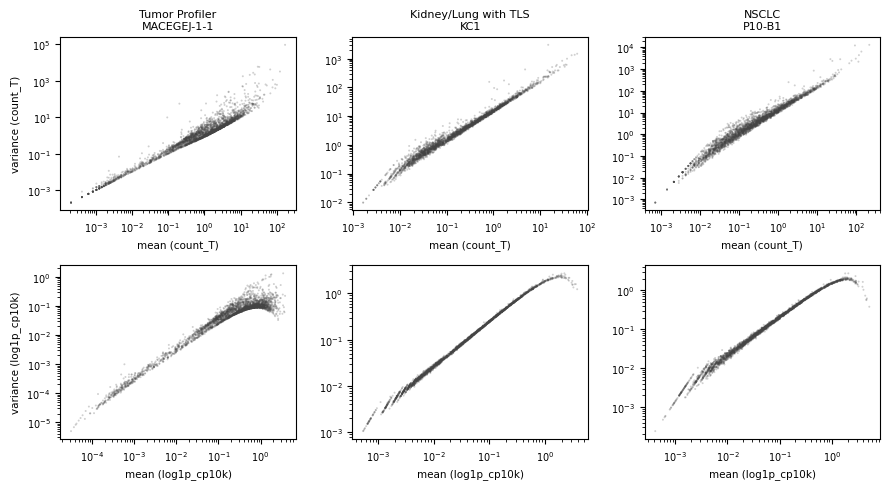

CONTROL VIEW (not saved, GENE AXIS): one point per gene, one slide per column.


In [2]:
# Loaded here rather than in the config: only D1 reads this table.
f_msp = ANALYSIS / "rf_spot_meanvar.parquet"
MSP = pd.read_parquet(f_msp) if f_msp.is_file() else None

AXIS_D1 = {
    "gene": ["AXIS GENE  one point per GENE: mean and variance across the slide's SPOTS,",
             "           then Spearman over the panel's 3000 genes."],
    "spot": ["AXIS SPOT  one point per SPOT: level = y_sg (its own value), spread = v_g (that",
             "           gene's variance across the spots of the SAME slide), Spearman over the",
             "           spot's DETECTED genes, then median over the slide's spots."],
}

if MVS is None:
    print("D1 MISSING: run snake/scripts/reason_failure/launch_rf_gene_meanvar_precompute.sh")
elif "axis" not in MVS.columns:
    print("D1 STALE: rf_meanvar_spearman.parquet carries no 'axis' column. The precompute has")
    print("gained the spot axis since; relaunch with the launcher (it overwrites both parquets).")
else:
    for axis in ("gene", "spot"):
        sub_axis = MVS[MVS["axis"] == axis]
        if sub_axis.empty:
            continue
        print("=" * 122)
        for line in AXIS_D1[axis]:
            print("D1 " + line if line.startswith("AXIS") else line)
        print("=" * 122)
        print(f"  {'cohort':<22s} {'scale':<14s} {'Spearman(level, spread)':>27s}"
              f" {'log-log slope':>24s} {'med/slide':>9s} {'slides':>6s} {'units':>9s}")
        for ds in DATASETS:
            for scale in ("count_T", "log1p_cp10k"):
                sub = sub_axis[(sub_axis["dataset"] == ds) & (sub_axis["scale"] == scale)]
                if sub.empty:
                    continue
                print(f"  {DATASET_LABELS.get(ds, ds):<22s} {scale:<14s} "
                      f"{fmt(by_donor(sub, 'spearman', ds), 27)}"
                      f" {fmt(by_donor(sub, 'slope_loglog', ds))}"
                      f" {sub['spearman'].median():>+9.3f} {len(sub):>6d}"
                      f" {int(sub['n_units'].sum()):>9,d}")
        print()
    print("  A value is computed WITHIN a slide, averaged over a donor's slides, then over")
    print("  the donors with the Student CI. 'med/slide' is the raw median over slides, without")
    print("  going through the donor, as a control. 'units' = genes (gene axis) or spots with a")
    print("  defined value (spot axis). The log-log slope exists only on the gene axis: it needs")
    print("  a mean and a variance of the SAME variable, which the spot axis does not provide.")

    sp = MVS[MVS["axis"] == "spot"]
    if not sp.empty:
        cov = sp.groupby(["dataset", "scale"])[["n_units", "n_spots"]].sum()
        cov["pct_defini"] = (100 * cov["n_units"] / cov["n_spots"]).round(1)
        print()
        print("COVERAGE of the spot axis. A spot has no value if it has fewer than 60 detected genes,")
        print("or if all its detected values are equal (frequent on count_T, where many detected")
        print("genes are exactly 1). This is not a chosen filter, it is the data.")
        print(cov.to_string())

    # -- the naive dual, with its caveat --
    if MSP is not None:
        print()
        print("THE NAIVE DUAL (not to be reported alone): mean and variance TAKEN ACROSS THE")
        print("detected GENES of a spot, then Spearman over the slide's spots. A spot gives only")
        print("one draw per gene, so this variance is the dispersion of the spot's COMPOSITION")
        print("and estimates no conditional variance.")
        print(f"  {'cohort':<22s} {'scale':<14s} {'Spearman':>24s} {'slides':>6s}")
        for ds in DATASETS:
            d = MSP[MSP["dataset"] == ds]
            if d.empty:
                continue
            for scale in ("count_T", "log1p_cp10k"):
                per = []
                for slide, g in d.groupby("slide", observed=True):
                    m = g[f"mean_det_{scale}"].to_numpy()
                    v = g[f"var_det_{scale}"].to_numpy()
                    ok = np.isfinite(m) & np.isfinite(v)
                    rho = (float(stats.spearmanr(m[ok], v[ok])[0])
                           if ok.sum() > 2 and np.ptp(m[ok]) > 0 and np.ptp(v[ok]) > 0 else np.nan)
                    per.append(dict(slide=slide, spearman=rho))
                per = pd.DataFrame(per)
                print(f"  {DATASET_LABELS.get(ds, ds):<22s} {scale:<14s} "
                      f"{fmt(by_donor(per, 'spearman', ds))} {len(per):>6d}")

    # -- control view (NOT saved): the log-log scatter of the gene axis --
    if MV is not None:
        fig, axes = plt.subplots(2, len(DATASETS), figsize=(3.0 * len(DATASETS), 5.0), squeeze=False)
        for j, ds in enumerate(DATASETS):
            for i, scale in enumerate(("count_T", "log1p_cp10k")):
                ax = axes[i, j]
                d = MV[MV["dataset"] == ds]
                if d.empty:
                    continue
                # ONE slide, not all: stacking slides would make a scatter whose dispersion is
                # between-slide variation, while the estimand is within-slide.
                sl = sorted(d["slide"].unique())[0]
                d = d[d["slide"] == sl]
                m, v = d[f"mean_{scale}"].to_numpy(), d[f"var_{scale}"].to_numpy()
                ok = (m > 0) & (v > 0)
                ax.scatter(m[ok], v[ok], s=2.0, alpha=0.25, edgecolors="none", color="#444444")
                ax.set_xscale("log")
                ax.set_yscale("log")
                ax.tick_params(labelsize=7)
                if i == 0:
                    ax.set_title(f"{DATASET_LABELS.get(ds, ds)}\n{sl}", fontsize=8)
                if j == 0:
                    ax.set_ylabel(f"variance ({scale})", fontsize=7.5)
                ax.set_xlabel(f"mean ({scale})", fontsize=7.5)
        fig.tight_layout()
        plt.show()
        print("CONTROL VIEW (not saved, GENE AXIS): one point per gene, one slide per column.")

## D2. The model reproduces this spread

**No computation.** Internal reference to the same paper's calibration section (`fig:calibration`), not
an imported assumption.

The calibration error measures the gap between announced coverage and observed coverage: a
low value means the predicted spread agrees with the observed spread. The result is already
established on the three cohorts, with the negative binomial best specified, and **no head
degrading** relative to a distribution fitted directly on the data (the dashed
rows of `fig:calibration`).

**In short:**

> The fitted predictive reproduces that spread. The calibration results already show it: the calibration error
> is the departure between stated and observed coverage, and no head degrades it relative to a
> distribution fitted directly on the measurements, the negative binomial being the best specified.
> What a head learns from the image is therefore, in the main, the spread the data already have.

**Limitation.** Calibration is a property **aggregated** by (slide, gene). It establishes
agreement on average, not for a given prediction. That is precisely why it is not enough
and why D3 to D6 exist.

## D3. The predicted uncertainty orders the units like the predicted mean

**Question.** Do sigma and mu produce the same ranking?

**Estimand, on both axes**, computed **within a slide** then aggregated donor then cohort:

- **gene axis**: Spearman, over the 3000 genes, between the mean uncertainty per gene and the mean
  predicted per gene, both averaged across the **spots**;
- **spot axis**: the dual, Spearman over the slide's spots between the mean uncertainty per spot and
  the mean predicted per spot, both averaged across the **genes**.

The spot axis is where D4 finds the strongest coupling at the entry level, so its aggregated
counterpart is the more informative of the two.

**Expected.** Very high correlation, close to 1, on both axes.

**Limitation.** Both quantities are aggregated, so this diagnostic is
**mute on what happens inside a unit**, that is, at the level where the paper's
conclusion applies. It calls for its non-aggregated counterpart, D4a. Both quantities are moreover
**model outputs**: D3 measures a property of the model, not of the data.

**A caveat specific to the `pos` population on the spot axis.** The set of detected genes changes
from one spot to the next, so a per-spot mean over the detected ones covers a different gene set
per spot, and part of the contrast between spots is that composition. The `all` column, in turn,
reduces each spot over the same 3000 genes: that is the control to read alongside. On the gene axis,
the symmetry does not exist in the same way, all the slide's spots being available for each
gene.

In [3]:
# spot_slide.parquet: the exact dual of gene_slide.parquet, loaded here since only D3 and D6 read it.
SS = {}
for (ds, m), leaf in LEAF.items():
    f = leaf / "reason_failure" / "spot_slide.parquet"
    if f.is_file():
        SS[(ds, m)] = pd.read_parquet(f)


def d3_per_slide(df, pop):
    """One row per slide: Spearman(mean sigma, mean mu) over the axis units.

    The axis is carried by the table: gene_slide -> one unit per gene, spot_slide -> one per spot.
    The floor of 60 detections applies to n_pos in both cases. The ptp guard avoids
    asking for a rank on a constant input (the spot-homoscedastic Gaussian on the gene axis,
    the gene-homoscedastic one on the spot axis): this is a degeneracy by construction, not a
    result, and scipy would flag it with a warning per slide."""
    d = df if pop == "all" else df[df["n_pos"] >= N_PLUS_MIN]
    out = []
    for slide, g in d.groupby("slide", observed=True):
        u, m = g[f"mean_sigma_{pop}"].to_numpy(), g[f"mean_mu_{pop}"].to_numpy()
        ok = np.isfinite(u) & np.isfinite(m)
        rho = np.nan
        if ok.sum() > 2 and np.ptp(u[ok]) > 0 and np.ptp(m[ok]) > 0:
            rho = float(stats.spearmanr(u[ok], m[ok])[0])
        out.append(dict(slide=slide, n_units=int(ok.sum()), spearman=rho))
    return pd.DataFrame(out)


D3 = {}
if not GS:
    print("D3 MISSING: run snake/scripts/reason_failure/launch_rf_axes_precompute.sh")
else:
    for axis, TAB, unit in (("gene", GS, "genes"), ("spot", SS, "spots")):
        if not TAB:
            print(f"D3 axis {axis} MISSING: relaunch the precompute (FORCE=1), it gained the spot axis.")
            continue
        print("=" * 122)
        if axis == "gene":
            print("D3 GENE AXIS  Spearman(mean sigma per gene, mean mu per gene) WITHIN a slide,")
            print("              both means taken across the SPOTS, over the 3000 genes.")
        else:
            print("D3 SPOT AXIS  Spearman(mean sigma per spot, mean mu per spot) WITHIN a slide,")
            print("              both means taken across the GENES, over the spots.")
        print("=" * 122)
        for ds in DATASETS:
            got = [m for m in MODELS if (ds, m) in TAB]
            if not got:
                continue
            print()
            print(f"--- {DATASET_LABELS.get(ds, ds)} ---")
            print(f"  {'head':<34s} {'detected (main)':>24s} {'all entries':>24s}"
                  f" {unit:>7s} {'slides':>6s}")
            for m in got:
                cells = {}
                for pop in ("pos", "all"):
                    per = d3_per_slide(TAB[(ds, m)], pop)
                    D3[(ds, m, axis, pop)] = per
                    cells[pop] = by_donor(per, "spearman", ds)
                per_pos = D3[(ds, m, axis, "pos")]
                print(f"  {MODEL_LABELS.get(m, m):<34s} {fmt(cells['pos'])} {fmt(cells['all'])}"
                      f" {int(per_pos['n_units'].median()):>7d} {len(per_pos):>6d}")
        print()
    print("  The units column is the per-slide median of the number of units kept on the")
    print("  detected population (floor of 60 detections per unit). 'mute' = constant quantity")
    print("  on this axis, so no rank: it is the analytic control, not a missing value.")
    print("  REMINDER: both quantities are model outputs and are aggregated. This table says")
    print("  nothing about what happens INSIDE a unit: that is D4a.")

D3 GENE AXIS  Spearman(mean sigma per gene, mean mu per gene) WITHIN a slide,
              both means taken across the SPOTS, over the 3000 genes.

--- Tumor Profiler ---
  head                                        detected (main)              all entries   genes slides
  Gaussian gene-homoscedastic        +0.5183 [+0.1568,+0.8798]* +0.5550 [+0.1577,+0.9523]*    2626     18
  Gaussian heteroscedastic           +0.9163 [+0.8892,+0.9434]* +0.9550 [+0.9421,+0.9679]*    2626     18
  Gaussian spot-homoscedastic        +0.0333 [-0.0648,+0.1314]                      mute    2626     18
  Poisson                            +0.9983 [+0.9976,+0.9991]* +0.9991 [+0.9986,+0.9995]*    2624     18
  Negative binomial                  +0.9736 [+0.9591,+0.9880]* +0.9911 [+0.9888,+0.9933]*    2624     18

--- Kidney/Lung with TLS ---
  head                                        detected (main)              all entries   genes slides
  Gaussian gene-homoscedastic        +0.5868 [+0.3244,+0.8493]* +0

## D4. Decomposition of the raw correlation at the entry level

**Question.** Within a given group, what has the uncertainty learned (D4a), and is it worth
anything for the error (D4b)?

**No new computation.** The three correlations that enter the partial are already written by
`canal2_uncertainty_precompute.py`, per group and per case, in `pair_partial.parquet` and
`spot_partial.parquet` :

$$\rho_{\mathcal{G}} = \frac{\rho_{u\Delta} - \rho_{u\mu}\rho_{\Delta\mu}}{\sqrt{(1-\rho_{u\mu}^2)(1-\rho_{\Delta\mu}^2)}}$$

| column | quantity |
|---|---|
| `r_um` | **D4a**, Spearman(sigma, mu) **within** the group |
| `r_Dm` | **D4b**, Spearman(error, mu) **within** the group |
| `r_uD` | the raw value, uncontrolled |
| `r_partial` | the controlled value, the one in figure 3 |

Same groups, same floor of 60 entries, same aggregation (groups -> donor -> cohort) as the
paper's figure: the aggregation code is that of `unc_error_correlations_classic.ipynb`, taken verbatim.

**The two groupings**, dual: `(gene, slide)` orders across a gene's **spots**;
`(slide, spot)` orders across a spot's **genes**.

**What D4 adds.** The raw correlation of 0.8 stops being an isolated fact: it
is the product of two correlations to the mean. Where `r_Dm` is high, the raw one is high; where
it is zero, it is zero. The contrast between the two axes becomes a consequence.

**Limitation.** D4 contains no information the partial does not already contain. Its
value is **interpretive**: it assigns each half its role.

**Beware the `lin_all` case** (the one in figure 3 of the paper): at `y = 0` the error IS `|mu|`, so
`r_Dm` tends to 1 there by construction and the raw one to `r_um`. That is a demonstration of the
confounder, not a measurement. That is exactly why the main one here is `lin_pos`.

In [4]:
def donor_points(frame, ds, axis, stat, case):
    """{donor: value} + the number of groups kept, for ONE (axis, statistic, case).

    Taken verbatim from notebooks/paper_figures/unc_error_correlations_classic.ipynb, with the case as parameter.
    The n >= 60 filter and the NaN removal happen HERE because the parquet carries ALL the groups.
    On the gene axis the fold-up is in two steps, groups -> (gene, donor) weighted by the group
    size, then plain mean over the donor's genes; on the spot axis a spot belongs to one
    slide hence to one donor, and the mean is direct."""
    col, ncol = f"{stat}_{case}", N_COL[case]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return {}, 0
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return {}, 0
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    if axis == "spot":
        return d.groupby(donor.to_numpy())[col].mean().to_dict(), int(len(d))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]
    return g.groupby("donor")["v"].mean().to_dict(), int(len(d))


STATS4 = [("r_um", "D4a  sigma ~ mu"), ("r_Dm", "D4b  error ~ mu"),
          ("r_uD", "raw  sigma ~ error"), ("r_partial", "controlled")]

D4 = {}
for (ds, m) in sorted(set(PAIR) | set(SPOT)):
    for axis in AXES:
        frame = (PAIR if axis == "gene" else SPOT).get((ds, m))
        for case in CASES:
            rec = {}
            for stat, _lab in STATS4:
                pts, n = donor_points(frame, ds, axis, stat, case)
                rec[stat] = dstat(pts) if pts else dict(mean=np.nan, lo=np.nan, hi=np.nan, K=0)
                rec["n_groups"] = n
            D4[(ds, m, axis, case)] = rec

for case in ([CASE_MAIN] + [c for c in CASES if c != CASE_MAIN]):
    tag = "PRINCIPAL" if case == CASE_MAIN else "robustness"
    print("#" * 130)
    print(f"# D4  CASE {case.upper()} ({tag}) - {CASE_FIG[case]}")
    print("#" * 130)
    for axis in AXES:
        grouping = ("one group per (gene, slide), across that gene's SPOTS" if axis == "gene"
                    else "one group per (slide, spot), across that spot's GENES")
        print()
        print(f"=== axis {axis}: {grouping} ===")
        for ds in DATASETS:
            got = [m for m in MODELS if (ds, m, axis, case) in D4]
            if not got:
                continue
            print()
            print(f"--- {DATASET_LABELS.get(ds, ds)} ---")
            print(f"  {'head':<34s} " + " ".join(f"{lab:>24s}" for _s, lab in STATS4) + "  groups")
            for m in got:
                rec = D4[(ds, m, axis, case)]
                print(f"  {MODEL_LABELS.get(m, m):<34s} "
                      + " ".join(fmt(rec[s]) for s, _lab in STATS4)
                      + f"  {rec['n_groups']:>7,d}")
    print()

print("=" * 130)
print("CHECK 1, MANDATORY: the identity of the partial, group by group.")
print("  r_partial must equal (r_uD - r_um*r_Dm) / sqrt((1 - r_um^2)(1 - r_Dm^2)) on EVERY")
print("  group. A gap signals an extraction error, not a result.")
print("=" * 130)
worst = 0.0
for (ds, m), fr in list(PAIR.items()) + list(SPOT.items()):
    for case in CASES:
        cols = [f"{s}_{case}" for s, _l in STATS4]
        if not all(c in fr.columns for c in cols):
            continue
        u, e, d_, p = (fr[c].to_numpy() for c in cols)
        den = np.sqrt((1 - u ** 2) * (1 - e ** 2))
        with np.errstate(invalid="ignore", divide="ignore"):
            rebuilt = (d_ - u * e) / den
        ok = np.isfinite(rebuilt) & np.isfinite(p)
        if ok.sum():
            worst = max(worst, float(np.abs(rebuilt[ok] - p[ok]).max()))
print(f"  maximum gap over all groups, all cohorts, all heads: {worst:.2e}")
print("  (expected ~1e-12: the same formula, recomputed from the three extracted columns)")

##################################################################################################################################
# D4  CASE LIN_POS (PRINCIPAL) - |y - mu|, detected entries only (y > 0)
##################################################################################################################################

=== axis gene: one group per (gene, slide), across that gene's SPOTS ===

--- Tumor Profiler ---
  head                                        D4a  sigma ~ mu          D4b  error ~ mu       raw  sigma ~ error               controlled  groups
  Gaussian gene-homoscedastic                            mute -0.0474 [-0.1001,+0.0054]                      mute                     mute        0
  Gaussian heteroscedastic           +0.1773 [+0.1043,+0.2503]* -0.0232 [-0.0717,+0.0253]  +0.1051 [+0.0542,+0.1559]* +0.1156 [+0.0683,+0.1629]*   47,228
  Gaussian spot-homoscedastic        -0.1085 [-0.1855,-0.0316]* -0.0400 [-0.0996,+0.0197]  +0.1492 [+0.0813,+0.2172]* +0

CHECK 2: the numerator vanishes if and only if r_uD = r_um * r_Dm. On the groups
where the controlled one is close to zero, the points must fall on the diagonal.
  cohort                 head                               axis   med |r_uD - r_um.r_Dm| |controlled|<0.1
  Tumor Profiler         Gaussian gene-homoscedastic        spot                   0.0659            62.5%
  Tumor Profiler         Gaussian heteroscedastic           gene                   0.0707            49.2%
  Tumor Profiler         Gaussian heteroscedastic           spot                   0.0276            81.6%
  Tumor Profiler         Gaussian spot-homoscedastic        gene                   0.0921            44.9%
  Tumor Profiler         Poisson                            gene                   0.0000             0.0%
  Tumor Profiler         Poisson                            spot                   0.0000             0.0%
  Tumor Profiler         Negative binomial                  gene                   0.0488

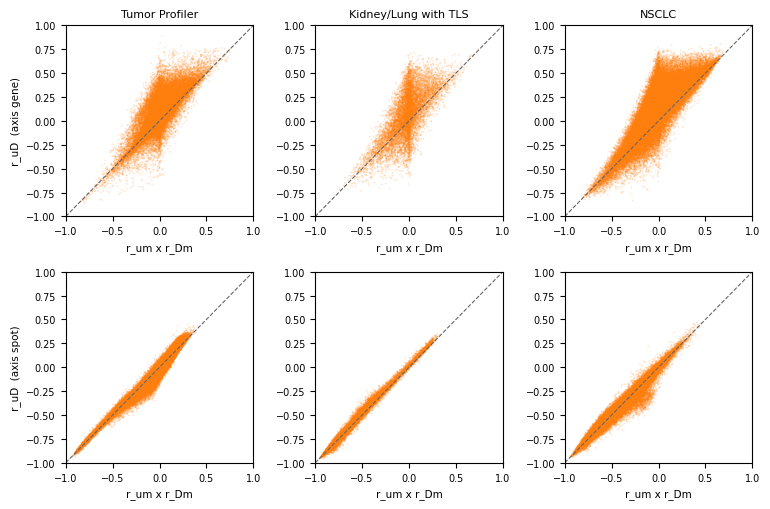

CONTROL VIEW (not saved): Gaussian heteroscedastic, case lin_pos. One point per group.


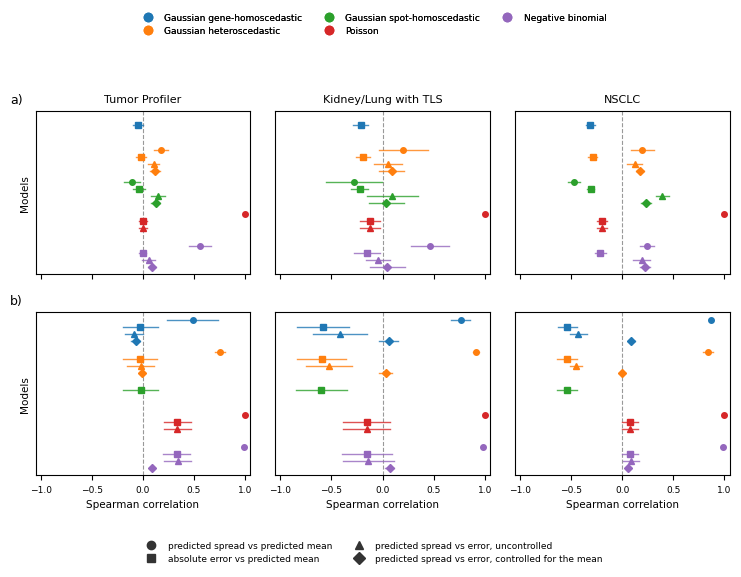

## FIGURE  fig_reason_failure_decomposition_lin_pos_pr_classic3.pdf
## TITLE   The uncontrolled error-uncertainty correlation is the product of two correlations with the predicted mean
## CAPTION Every quantity is a Spearman correlation computed INSIDE a group, then averaged over
## CAPTION the groups of a held-out donor; the point is the mean over donors and the bar its
## CAPTION Student-t 95% interval. Color identifies the predictive head, SHAPE the quantity.
## CAPTION o = predicted spread vs predicted mean.
## CAPTION s = absolute error vs predicted mean.
## CAPTION ^ = predicted spread vs error, uncontrolled.
## CAPTION D = predicted spread vs error, controlled for the mean.
## CAPTION a) one group per gene and slide, ranking across the spots of that gene;
## CAPTION b) one group per slide and spot, ranking across the genes of that spot.
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION A missing marker is a head MUTE by construction on that groupin

In [5]:
# ---- CHECK 2 (interpretive) + THE FIGURE ----
from matplotlib.lines import Line2D

FIGDIR.mkdir(parents=True, exist_ok=True)


def fig_show(fig, stem, title, caption):
    """Saves .pdf + .png, displays, then PRINTS title and caption."""
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


print("CHECK 2: the numerator vanishes if and only if r_uD = r_um * r_Dm. On the groups")
print("where the controlled one is close to zero, the points must fall on the diagonal.")
print(f"  {'cohort':<22s} {'head':<34s} {'axis':<5s} {'med |r_uD - r_um.r_Dm|':>23s} {'|controlled|<0.1':>16s}")
for ds in DATASETS:
    for m in MODELS:
        for axis in AXES:
            fr = (PAIR if axis == "gene" else SPOT).get((ds, m))
            if fr is None:
                continue
            cols = [f"{s}_{CASE_MAIN}" for s, _l in STATS4]
            if not all(c in fr.columns for c in cols):
                continue
            keep = fr[fr[N_COL[CASE_MAIN]] >= N_PLUS_MIN]
            u, e, d_, p = (keep[c].to_numpy() for c in cols)
            ok = np.isfinite(u) & np.isfinite(e) & np.isfinite(d_)
            if ok.sum() < 10:
                continue
            gap = np.abs(d_[ok] - u[ok] * e[ok])
            near = np.isfinite(p[ok]) & (np.abs(p[ok]) < 0.1)
            print(f"  {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(m, m):<34s} {axis:<5s} "
                  f"{np.median(gap):>23.4f} {100 * near.mean():>15.1f}%")

# -- control view (NOT saved): the diagonal scatter, main head only --
fig, axes = plt.subplots(len(AXES), len(DATASETS), figsize=(2.6 * len(DATASETS), 2.6 * len(AXES)),
                         squeeze=False)
for i, axis in enumerate(AXES):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        fr = (PAIR if axis == "gene" else SPOT).get((ds, PRINCIPAL))
        if fr is None:
            ax.set_axis_off()
            continue
        keep = fr[fr[N_COL[CASE_MAIN]] >= N_PLUS_MIN]
        u = keep[f"r_um_{CASE_MAIN}"].to_numpy()
        e = keep[f"r_Dm_{CASE_MAIN}"].to_numpy()
        d_ = keep[f"r_uD_{CASE_MAIN}"].to_numpy()
        ax.scatter(u * e, d_, s=1.5, alpha=0.2, edgecolors="none",
                   color=MODEL_COLORS.get(PRINCIPAL, "0.3"))
        ax.plot([-1, 1], [-1, 1], color="0.4", lw=0.8, ls="--")
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1, 1)
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
        if j == 0:
            ax.set_ylabel(f"r_uD  (axis {axis})", fontsize=7.5)
        ax.set_xlabel("r_um x r_Dm", fontsize=7.5)
fig.tight_layout()
plt.show()
print(f"CONTROL VIEW (not saved): {MODEL_LABELS.get(PRINCIPAL, PRINCIPAL)}, case "
      f"{CASE_MAIN}. One point per group.")

# ---- THE saved figure ----
GAP, STEP = 0.75, 3.4
MARKERS = {"r_um": "o", "r_Dm": "s", "r_uD": "^", "r_partial": "D"}
MARK_LAB = {"r_um": "predicted spread vs predicted mean",
            "r_Dm": "absolute error vs predicted mean",
            "r_uD": "predicted spread vs error, uncontrolled",
            "r_partial": "predicted spread vs error, controlled for the mean"}

fig, axes = plt.subplots(len(AXES), len(DATASETS),
                         figsize=(2.5 * len(DATASETS), 2.6 * len(AXES)), sharex=True)
axes = np.atleast_2d(axes)
drawn = []
for i, axis in enumerate(AXES):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        for k, m in enumerate(MODELS):
            rec = D4.get((ds, m, axis, CASE_MAIN))
            if rec is None:
                continue
            c = MODEL_COLORS.get(m, "0.4")
            for t, (stat, _lab) in enumerate(STATS4):
                st = rec[stat]
                y = k * STEP + t * GAP
                if not np.isfinite(st["mean"]):
                    continue
                if np.isfinite(st["lo"]):
                    ax.plot([st["lo"], st["hi"]], [y, y], color=c, lw=1.0, alpha=0.8, zorder=3)
                ax.plot([st["mean"]], [y], MARKERS[stat], ms=4.0, color=c, zorder=4)
                drawn.append(dict(axis=axis, dataset=ds, model=m, stat=stat, **st))
        ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
        ax.set_xlim(-1.05, 1.05)
        ax.set_yticks([])
        ax.set_ylim(-0.8, (len(MODELS) - 1) * STEP + (len(STATS4) - 1) * GAP + 0.8)
        ax.invert_yaxis()
        ax.tick_params(axis="x", labelsize=6.5)
        if j == 0:
            ax.set_ylabel("Models", fontsize=7.5)
            ax.text(-0.06, 1.03, f"{'ab'[i]})", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=9)
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
        if i == len(AXES) - 1:
            ax.set_xlabel("Spearman correlation", fontsize=7.5)

model_handles = [Line2D([], [], marker="o", ls="", color=MODEL_COLORS.get(m, "0.4"),
                        label=MODEL_LABELS.get(m, m)) for m in MODELS]
stat_handles = [Line2D([], [], marker=MARKERS[s], ls="", color="#333333", label=MARK_LAB[s])
                for s, _l in STATS4]
fig.tight_layout(rect=(0, 0, 1, 0.86))
leg1 = fig.legend(handles=model_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
                  ncol=3, frameon=False, fontsize=6.5)
fig.add_artist(leg1)
fig.legend(handles=stat_handles, loc="lower center", ncol=2, frameon=False, fontsize=6.5,
           bbox_to_anchor=(0.5, -0.09))

fig_show(fig, FIGDIR / f"fig_reason_failure_decomposition_{CASE_MAIN}_{RUN_ID}",
         "The uncontrolled error-uncertainty correlation is the product of two correlations "
         "with the predicted mean",
         ["Every quantity is a Spearman correlation computed INSIDE a group, then averaged over",
          "the groups of a held-out donor; the point is the mean over donors and the bar its",
          "Student-t 95% interval. Color identifies the predictive head, SHAPE the quantity.",
          *[f"{MARKERS[s]} = {MARK_LAB[s]}." for s, _l in STATS4],
          "a) one group per gene and slide, ranking across the spots of that gene;",
          "b) one group per slide and spot, ranking across the genes of that spot.",
          f"Error definition: {CASE_FIG[CASE_MAIN]}.",
          "A missing marker is a head MUTE by construction on that grouping, not a missing",
          "measurement: its predicted spread is constant inside the group, or is a monotone",
          "function of the predicted mean, in which case the partial correlation does not exist.",
          "The uncontrolled value sits high wherever both correlations with the mean are high,",
          "and collapses wherever the error stops following the mean, which is what the partial",
          "correlation removes."])

DRAWN = pd.DataFrame(drawn)
print()
print("THE PRINTED TWIN OF THE FIGURE - exactly the plotted values")
print(f"  {'axis':<5s} {'cohort':<22s} {'head':<34s} {'quantity':<10s} {'value':>24s} {'K':>3s}")
for _, r in DRAWN.iterrows():
    print(f"  {r['axis']:<5s} {DATASET_LABELS.get(r['dataset'], r['dataset']):<22s} "
          f"{MODEL_LABELS.get(r['model'], r['model']):<34s} {r['stat']:<10s} "
          f"{fmt(r.to_dict())} {int(r['K']):>3d}")

## D5. Wrong axis: variance decomposition gene versus spot

**Question.** Do the uncertainty and the error vary along the same axes?

**Estimand.** The share of total variance attributable to the gene factor and to the spot factor,
separately for `log(sigma)` and for `log|error|`. On a (spots x genes) matrix, with `a_j` the
mean of column `j`, `b_i` that of row `i` and `g` the overall mean:

$$SS_{\text{gene}} = n_{\text{spots}}\sum_j (a_j-g)^2, \qquad SS_{\text{spot}} = n_{\text{genes}}\sum_i (b_i-g)^2, \qquad SS_{\text{resid}} = SS_{\text{tot}} - SS_{\text{gene}} - SS_{\text{spot}}$$

**The readable quantity is the GAP** between the gene share of `log(sigma)` and that of `log|error|`,
never the level of the former: if the error too were at 0.9 at the gene level, the model
would be right instead of redundant.

**Two versions, read together.**

| | source | resolution | population | floor |
|---|---|---|---|---|
| **A, reported** | `bio_axis/variance_shares.parquet` | per **donor** | all entries | one eps |
| **B, robustness** | `reason_failure/variance_shares_slide.parquet` | per **slide** | detected + all | two eps + ranks |

B answers the three rigor points A does not address:

1. **per slide and not per donor.** A spot belongs to a single slide; on a multi-section
   donor (TuPro, NSCLC) the slide effect would carry over onto the spot effect and inflate
   `share_spot`.
2. **the third term is RESIDUAL, not an interaction.** Without repeats, interaction and noise
   are not separately identifiable.
3. **sensitivity to eps.** On the error, too small an eps creates a left tail as soon as an error
   is near zero, which inflates `SS_tot` and mechanically crushes both shares. Hence two
   eps values (1 % and 10 % of the median of the slice's positive errors) **and** a version
   on the **within-slide ranks**, which removes the question: any strictly increasing transform
   gives the same ranks. The problem does not arise on `log(sigma)`, strictly positive.

**A reading warning on the detected population.** The matrix is incomplete there, so the
two-factor design is no longer orthogonal: the shares may not sum exactly to 1 and the
split between gene and spot is no longer unique. `share_sum` is printed so that this gap is
visible rather than hidden.

**Built-in analytic control.** The gene-homoscedastic Gaussian learns one variance per gene,
so `share_gene(log sigma)` must equal 1 exactly. If it does not, the cell is
wrong, not the model.

**What D5 establishes.** An uncertainty nearly constant inside a spot cannot order
errors that do vary at that level. The obstruction is structural, not quantitative.

In [6]:
# ---- D5 version A: per DONOR, the version already reported (bio_axis) ----
if not BIO:
    print("D5-A MISSING: bio_axis has not run on this run")
    print("   -> DRYRUN=1 bash snake/scripts/bio/launch_bio_axis_precompute.sh")
else:
    print("=" * 118)
    print("D5-A  PER DONOR, all entries (bio_axis) - the reported version")
    print("=" * 118)
    for (ds, m), sh in sorted(BIO.items()):
        piv = sh.pivot_table(index="test_donor", columns="quantity",
                             values=["share_gene", "share_spot", "share_interaction"])
        print()
        print(f"--- {DATASET_LABELS.get(ds, ds)} / {MODEL_LABELS.get(m, m)} ---")
        print(sh.groupby("quantity")[["share_gene", "share_spot", "share_interaction",
                                      "sd_interaction"]].agg(["mean", "std"]).round(4).to_string())
        gapd = (piv["share_gene"]["log_sigma"] - piv["share_gene"]["log_abs_err"]).dropna()
        st = dstat(gapd.to_dict())
        print(f"  GAP share_gene(log sigma) - share_gene(log |error|): {fmt(st)}"
              f"   ({int((gapd > 0).sum())}/{len(gapd)} donors > 0)")
        print("  per donor: " + "  ".join(f"{d}={v:+.4f}" for d, v in gapd.items()))

D5-A  PER DONOR, all entries (bio_axis) - the reported version

--- Tumor Profiler / Gaussian heteroscedastic ---
            share_gene         share_spot         share_interaction         sd_interaction        
                  mean     std       mean     std              mean     std           mean     std
quantity                                                                                          
log_abs_err     0.7509  0.0321     0.0059  0.0029            0.2432  0.0311         0.9525  0.0523
log_sigma       0.9076  0.0239     0.0523  0.0183            0.0401  0.0118         0.1902  0.0274
  GAP share_gene(log sigma) - share_gene(log |error|): +0.1566 [+0.1353,+0.1780]*   (7/7 donors > 0)
  per donor: MACEGEJ=+0.1879  MAHEFOG=+0.1589  MAJOFIJ=+0.1724  MAKYGIW=+0.1191  MANOFYB=+0.1477  MELIPIT=+0.1398  MIDEKOG=+0.1707

--- NSCLC / Gaussian heteroscedastic ---
            share_gene         share_spot         share_interaction         sd_interaction        
                  

In [7]:
# ---- D5 version B: per SLIDE, detected and all, two eps and the ranks ----
if not SH:
    print("D5-B MISSING: run snake/scripts/reason_failure/launch_rf_axes_precompute.sh")
else:
    print("=" * 128)
    print("D5-B  PER SLIDE (robustness). The gap is share_gene(log sigma) - share_gene(log |err|),")
    print("      both read on the SAME population, with the paired transform for the error.")
    print("=" * 128)
    # sigma has no eps; it is therefore paired with each error transform: log <-> log_eps*,
    # rank <-> rank. Comparing a log sigma to a ranked error would make no sense.
    PAIRING = [("pos", "log", "log_eps1"), ("pos", "log", "log_eps10"), ("pos", "rank", "rank"),
               ("all", "log", "log_eps1"), ("all", "log", "log_eps10"), ("all", "rank", "rank")]
    D5B = {}
    for ds in DATASETS:
        got = [m for m in MODELS if (ds, m) in SH]
        if not got:
            continue
        print()
        print(f"--- {DATASET_LABELS.get(ds, ds)} ---")
        print(f"  {'head':<34s} {'pop':<4s} {'err. transform':<11s} {'gene share sigma':>17s}"
              f" {'gene share error':>17s} {'GAP':>24s}")
        for m in got:
            sh = SH[(ds, m)]
            for pop, t_sig, t_err in PAIRING:
                a = sh[(sh["population"] == pop) & (sh["quantity"] == "log_sigma")
                       & (sh["transform"] == t_sig)].set_index("slide")
                b = sh[(sh["population"] == pop) & (sh["quantity"] == "log_abs_err")
                       & (sh["transform"] == t_err)].set_index("slide")
                if a.empty or b.empty:
                    continue
                j = pd.DataFrame({"slide": a.index,
                                  "sig": a["share_gene"].to_numpy(),
                                  "err": b["share_gene"].reindex(a.index).to_numpy()})
                j["gap"] = j["sig"] - j["err"]
                st_s, st_e = by_donor(j, "sig", ds), by_donor(j, "err", ds)
                st_g = by_donor(j, "gap", ds)
                D5B[(ds, m, pop, t_err)] = dict(sigma=st_s, err=st_e, gap=st_g, n_slides=len(j))
                print(f"  {MODEL_LABELS.get(m, m):<34s} {pop:<4s} {t_err:<11s} "
                      f"{st_s['mean']:>17.4f} {st_e['mean']:>17.4f} {fmt(st_g)}")

    print()
    print("-- ANALYTIC CONTROL: the gene-homoscedastic Gaussian has ONE sigma per gene, so")
    print("   share_gene(log sigma) must equal 1 exactly. This is a test of the cell.")
    for ds in DATASETS:
        sh = SH.get((ds, "homoscedastic"))
        if sh is None:
            continue
        v = sh[(sh["quantity"] == "log_sigma") & (sh["transform"] == "log")]["share_gene"]
        flag = "OK " if np.allclose(v, 1.0, atol=1e-6) else "(!)"
        print(f"   {flag} {DATASET_LABELS.get(ds, ds):<22s} min {v.min():.8f}  max {v.max():.8f}")

    print()
    print("-- CHECK: orthogonality. share_sum equals 1 exactly on the COMPLETE matrix; a")
    print("   gap on the detected population is the unbalanced design, and it bounds the trust")
    print("   one can put in the gene/spot SPLIT (the gap itself stays readable).")
    allsh = pd.concat(SH.values(), ignore_index=True)
    print(allsh.groupby("population")["share_sum"].agg(["min", "median", "max"]).round(6).to_string())
    print()
    print("-- The full SPLIT (gene / spot / residual shares), main head, detected")
    print("   population, rank transform: this is the version with no floor choice at all.")
    for ds in DATASETS:
        sh = SH.get((ds, PRINCIPAL))
        if sh is None:
            continue
        d = sh[(sh["population"] == "pos") & (sh["transform"] == "rank")]
        print(f"   {DATASET_LABELS.get(ds, ds)}")
        print(d.groupby("quantity")[["share_gene", "share_spot", "share_resid"]]
               .agg(["mean", "std"]).round(4).to_string())

D5-B  PER SLIDE (robustness). The gap is share_gene(log sigma) - share_gene(log |err|),
      both read on the SAME population, with the paired transform for the error.

--- Tumor Profiler ---
  head                               pop  err. transform  gene share sigma  gene share error                      GAP
  Gaussian gene-homoscedastic        pos  log_eps1               1.0000            0.1858 +0.8142 [+0.7773,+0.8511]*
  Gaussian gene-homoscedastic        pos  log_eps10              1.0000            0.2153 +0.7847 [+0.7400,+0.8295]*
  Gaussian gene-homoscedastic        pos  rank                   1.0000            0.2200 +0.7800 [+0.7338,+0.8261]*
  Gaussian gene-homoscedastic        all  log_eps1               1.0000            0.6396 +0.3604 [+0.3136,+0.4072]*
  Gaussian gene-homoscedastic        all  log_eps10              1.0000            0.6020 +0.3980 [+0.3590,+0.4370]*
  Gaussian gene-homoscedastic        all  rank                   1.0000            0.5533 +0.4467 [+0.40

## D6. Bad amplitude

**Question.** Where the uncertainty can vary, does it vary as much as the error?

**Estimand.** The interquantile ratio of sigma and that of the error, **inside a
unit**: per cell of at least 60 detected entries,

$$r_u = \frac{p_{90}(\hat\sigma)}{p_{10}(\hat\sigma)}, \qquad r_\Delta = \frac{p_{90}(\Delta)}{p_{10}(\Delta)}$$

then median over a slide's cells, mean over a donor's slides, Student over the
donors. Percentiles rather than the extremes, for robustness. Both axes: cell =
(gene, slide), across the spots; and cell = (spot, slide), across the genes.

A ratio is **invariant to a multiplicative constant**, so comparing `r_u` and `r_Delta` is
legitimate although sigma and the error are not in the same unit depending on the family: within a
head, the two live on the same scale by construction (convention 4).

**The population, to read BEFORE the ratios.** These numbers do not cover all entries.
Two filters apply and the cell prints both of them: the **undetected** entries
are excluded (convention 2), and a cell enters only if it reaches **60 detected entries**.
On the sparse cohorts this drops a large share of the cells, and that is a fact to cite, not to
hide.

**Rigor point.** `p10(Delta)` can be near zero on sparse genes and make
`r_Delta` diverge. Zero-denominator cells are counted and excluded, the count is printed, and
the `p90/p50` fallback is reported for both quantities: if the two versions do not say the same
thing, the second one is what counts.

**Expected.** `r_u` clearly below `r_Delta` on the gene axis. On the spot axis we expect
the opposite for `r_u` itself, which must be large there: at fixed spot, mu spans several orders of
magnitude and sigma follows it. This is not a contradiction, it is the same law `v = f(m)` read on its
other axis, and what matters remains the **ratio** between the two amplitudes.

In [8]:
def d6_per_slide(df, hi="p90", lo="p10"):
    """One row per slide: median over its cells of both ratios, on the DETECTED ones.

    The axis is carried by the table (gene_slide -> cell = one gene; spot_slide -> one spot). A
    cell enters only if it has >= 60 detected entries AND a strictly positive denominator
    for BOTH quantities, otherwise the two medians would not cover the same cells and
    their ratio would mean nothing. Also returns what is needed to print what was dropped."""
    n_all = len(df)
    d = df[df["n_pos"] >= N_PLUS_MIN].copy()
    su, sl = d[f"sigma_{hi}_pos"].to_numpy(), d[f"sigma_{lo}_pos"].to_numpy()
    eu, el = d[f"err_{hi}_pos"].to_numpy(), d[f"err_{lo}_pos"].to_numpy()
    ok = (sl > 0) & (el > 0) & np.isfinite(su) & np.isfinite(eu)
    d["r_u"] = np.where(ok, su / np.where(sl > 0, sl, np.nan), np.nan)
    d["r_D"] = np.where(ok, eu / np.where(el > 0, el, np.nan), np.nan)
    per = (d.groupby("slide", observed=True)
            .agg(r_u=("r_u", "median"), r_D=("r_D", "median"), n_used=("r_u", "count"))
            .reset_index())
    return per, dict(n_possible=n_all, n_floor=int(len(d)), n_zero_den=int((~ok).sum()))


if not GS:
    print("D6 MISSING: run snake/scripts/reason_failure/launch_rf_axes_precompute.sh")
else:
    # ---- THE POPULATION FIRST. Without this block, the ratios read as if they covered
    # the whole panel, which is far from true on the sparse cohorts.
    print("=" * 124)
    print("THE POPULATION, before any ratio. Nothing here covers all entries.")
    print("=" * 124)
    print(f"  {'cohort':<22s} {'detected entries':>18s} {'gene cells >=60':>20s}"
          f" {'cells spot >=60':>20s}")
    for ds in DATASETS:
        g = GS.get((ds, PRINCIPAL))
        s = SS.get((ds, PRINCIPAL))
        if g is None:
            continue
        pct_det = 100 * g["n_pos"].sum() / g["n_spots"].sum()
        kg, ng = int((g["n_pos"] >= N_PLUS_MIN).sum()), len(g)
        cg = f"{kg:,}/{ng:,} ({100 * kg / ng:.0f}%)"
        if s is None:
            cs = "n/a"
        else:
            ks, ns = int((s["n_pos"] >= N_PLUS_MIN).sum()), len(s)
            cs = f"{ks:,}/{ns:,} ({100 * ks / ns:.0f}%)"
        print(f"  {DATASET_LABELS.get(ds, ds):<22s} {pct_det:>17.1f}% {cg:>20s} {cs:>20s}")
    print()
    print("  'detected entries' = share of (spot, gene) pairs where the model target is > 0;")
    print("  it is the population the percentiles are taken on. 'cells >= 60' = share")
    print("  of the axis cells that reach the floor, hence what is left after filtering.")
    print("  On the sparse cohorts both numbers are very far from 100 %, and that is the data.")
    print()

    D6, D6_POP = {}, {}
    for axis, TAB, cellname in (("gene", GS, "cell = (gene, slide), across the SPOTS"),
                                ("spot", SS, "cell = (spot, slide), across the GENES")):
        if not TAB:
            print(f"D6 axis {axis} MISSING: relaunch the precompute (FORCE=1).")
            continue
        for hi, lo in (("p90", "p10"), ("p90", "p50")):
            print("=" * 124)
            print(f"D6 {axis.upper()} AXIS  ratio {hi}/{lo}, detected entries, {cellname}")
            print("=" * 124)
            for ds in DATASETS:
                got = [m for m in MODELS if (ds, m) in TAB]
                if not got:
                    continue
                print()
                print(f"--- {DATASET_LABELS.get(ds, ds)} ---")
                print(f"  {'head':<34s} {'uncertainty r_u':>24s} {'error r_D':>24s}"
                      f" {'r_D / r_u':>10s} {'cells':>10s}")
                for m in got:
                    per, pop = d6_per_slide(TAB[(ds, m)], hi, lo)
                    su, se = by_donor(per, "r_u", ds), by_donor(per, "r_D", ds)
                    D6[(ds, m, axis, hi, lo)] = dict(u=su, e=se, **pop)
                    D6_POP[(ds, m, axis, hi, lo)] = pop
                    ratio = (se["mean"] / su["mean"]
                             if np.isfinite(su["mean"]) and su["mean"] else np.nan)
                    print(f"  {MODEL_LABELS.get(m, m):<34s} {fmt(su)} {fmt(se)} {ratio:>10.2f}"
                          f" {pop['n_floor']:>10,d}")
            print()
    print("  'cells' = kept cells, that is, those that reach the floor of 60 detected")
    print("  entries. The population table above says what share of the possible")
    print("  this represents.")
    zero_den = sorted({(k[0], k[1], k[2], f'{k[3]}/{k[4]}', v['n_zero_den'])
                       for k, v in D6_POP.items() if v['n_zero_den'] > 0})
    if zero_den:
        print("  Cells dropped in addition for a zero denominator (p10 exactly 0):")
        for ds, m, axis, ratio, n in zero_den:
            print(f"    {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(m, m):<34s} "
                  f"axis {axis:<5s} {ratio:<8s} {n:,}")
    else:
        print("  No cell dropped for a zero denominator: on the detected entries, p10 of")
        print("  |y - mu| is never exactly zero, which would require mu == y bit for bit.")
    print("  r_D / r_u > 1 means the error spans a wider range than the uncertainty,")
    print("  inside the unit, where the uncertainty is nonetheless allowed to vary.")

THE POPULATION, before any ratio. Nothing here covers all entries.
  cohort                   detected entries      gene cells >=60      cells spot >=60
  Tumor Profiler                      48.8%  47,228/54,000 (87%) 77,269/77,338 (100%)
  Kidney/Lung with TLS                11.4%  10,796/18,000 (60%)  18,114/19,437 (93%)
  NSCLC                               17.4% 69,055/108,000 (64%)  67,163/68,659 (98%)

  'detected entries' = share of (spot, gene) pairs where the model target is > 0;
  it is the population the percentiles are taken on. 'cells >= 60' = share
  of the axis cells that reach the floor, hence what is left after filtering.
  On the sparse cohorts both numbers are very far from 100 %, and that is the data.

D6 GENE AXIS  ratio p90/p10, detected entries, cell = (gene, slide), across the SPOTS

--- Tumor Profiler ---
  head                                        uncertainty r_u                error r_D  r_D / r_u      cells
  Gaussian gene-homoscedastic        +1.0000 [+1.

## What this plan does not establish

Three limitations that belong with the validity conditions.

1. **This explains what the uncertainty learns, not what it could have learned.** It does
   not settle between "the error is not predictable from the image" and "maximum likelihood
   is the wrong objective". A head trained directly on out-of-sample `|Delta|`, on the
   same frozen embeddings, would settle this point. It is not run here.
2. **A complementary explanation exists and is not excluded.** The squared error decomposes
   into conditional variance plus squared bias. At the correlations reached here, the bias term
   dominates. Yet a model able to predict its own bias would correct its mean instead of
   widening its variance: there is therefore an obstruction in principle to a likelihood
   learning the dominant component of the error. This reading is more general than the mean-variance
   coupling and compatible with it, the coupling then explaining what sigma learns in
   place.
3. **All the measurements are in-distribution.** They do not cover the behavior under
   batch, scanner or staining shift.

## Recap: the numbers to report

Reading order for writing the subsection:

1. **D1** establishes P1 on the data alone: the spread follows the level, on the scale of each
   family.
2. **D2** closes P1 by internal reference: the fitted predictive reproduces this spread.
3. **D4a** (`r_um`) gives P2 at the entry level, **D3** gives its per-gene aggregated counterpart.
4. **D4b** (`r_Dm`) gives P3, and the contrast between the two groupings becomes a consequence.
5. **D5** and **D6** give P4: wrong axis, then wrong amplitude.

Ranks 1 to 4 suffice to answer the question asked; 5 and 6 show that the failure is
structural.

In [9]:
print("=" * 118)
print(f"NUMBERS TO REPORT   run={RUN_ID}   main head = {MODEL_LABELS.get(PRINCIPAL, PRINCIPAL)}")
print(f"                     population main = {CASE_MAIN} ({CASE_FIG[CASE_MAIN]})")
print("=" * 118)

if MVS is not None and "axis" in MVS.columns:
    print("\nD1  mean-variance coupling in the DATA, per axis")
    for axis in ("gene", "spot"):
        for ds in DATASETS:
            for scale in ("count_T", "log1p_cp10k"):
                sub = MVS[(MVS["dataset"] == ds) & (MVS["scale"] == scale)
                          & (MVS["axis"] == axis)]
                if not sub.empty:
                    print(f"    axis {axis:<5s} {DATASET_LABELS.get(ds, ds):<22s} {scale:<14s} "
                          f"{fmt(by_donor(sub, 'spearman', ds))}")

if D3:
    print("\nD3  aggregated Spearman(sigma, mu), main head, detected")
    for axis in ("gene", "spot"):
        for ds in DATASETS:
            per = D3.get((ds, PRINCIPAL, axis, "pos"))
            if per is not None:
                print(f"    axis {axis:<5s} {DATASET_LABELS.get(ds, ds):<22s} "
                      f"{fmt(by_donor(per, 'spearman', ds))}")

print(f"\nD4  decomposition at the entry level, main head, case {CASE_MAIN}")
for axis in AXES:
    print(f"    axis {axis}")
    for ds in DATASETS:
        rec = D4.get((ds, PRINCIPAL, axis, CASE_MAIN))
        if rec is None:
            continue
        print(f"      {DATASET_LABELS.get(ds, ds):<22s} "
              + "  ".join(f"{s}={fmt(rec[s], 22)}" for s, _l in STATS4))

if BIO:
    print("\nD5-A  gene share gap (sigma minus error), PER DONOR, all entries")
    for (ds, m), sh in sorted(BIO.items()):
        piv = sh.pivot_table(index="test_donor", columns="quantity", values="share_gene")
        gapd = (piv["log_sigma"] - piv["log_abs_err"]).dropna()
        print(f"    {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(m, m):<34s} "
              f"{fmt(dstat(gapd.to_dict()))}")

if SH:
    print("\nD5-B  PER SLIDE, detected entries, ranks (no eps). The RESIDUAL share is the number")
    print("      to cite: it is the only term depending on both the spot and the gene, hence the only")
    print("      place where a PER-PREDICTION uncertainty can live.")
    for ds in DATASETS:
        sh = SH.get((ds, PRINCIPAL))
        r = D5B.get((ds, PRINCIPAL, "pos", "rank"))
        if sh is None or r is None:
            continue
        d = sh[(sh["population"] == "pos") & (sh["transform"] == "rank")]
        res = d.groupby("quantity")["share_resid"].mean()
        print(f"    {DATASET_LABELS.get(ds, ds):<22s} gene share gap {fmt(r['gap'], 22)}"
              f"   part residual : sigma {res.get('log_sigma', np.nan):.3f}"
              f"  error {res.get('log_abs_err', np.nan):.3f}")

if D6:
    print("\nD6  within-unit amplitude, main head (p90/p10, then the p90/p50 fallback)")
    for axis in ("gene", "spot"):
        for hi, lo in (("p90", "p10"), ("p90", "p50")):
            for ds in DATASETS:
                r = D6.get((ds, PRINCIPAL, axis, hi, lo))
                if r is not None:
                    print(f"    axis {axis:<5s} {DATASET_LABELS.get(ds, ds):<22s} {hi}/{lo}  "
                          f"sigma {fmt(r['u'], 22)}   error {fmt(r['e'], 22)}")

print(f"\nFigure written to {FIGDIR.relative_to(PROJ)}")


NUMBERS TO REPORT   run=pr_classic3   main head = Gaussian heteroscedastic
                     population main = lin_pos (|y - mu|, detected entries only (y > 0))

D1  mean-variance coupling in the DATA, per axis
    axis gene  Tumor Profiler         count_T        +0.9576 [+0.9294,+0.9858]*
    axis gene  Tumor Profiler         log1p_cp10k    +0.9535 [+0.9244,+0.9827]*
    axis gene  Kidney/Lung with TLS   count_T        +0.9815 [+0.9681,+0.9948]*
    axis gene  Kidney/Lung with TLS   log1p_cp10k    +0.9970 [+0.9940,+1.0000]*
    axis gene  NSCLC                  count_T        +0.9821 [+0.9776,+0.9867]*
    axis gene  NSCLC                  log1p_cp10k    +0.9948 [+0.9928,+0.9968]*
    axis spot  Tumor Profiler         count_T        +0.6519 [+0.5981,+0.7058]*
    axis spot  Tumor Profiler         log1p_cp10k    +0.5765 [+0.5096,+0.6433]*
    axis spot  Kidney/Lung with TLS   count_T        +0.5634 [+0.4796,+0.6473]*
    axis spot  Kidney/Lung with TLS   log1p_cp10k    +0.4656 [+0.3